
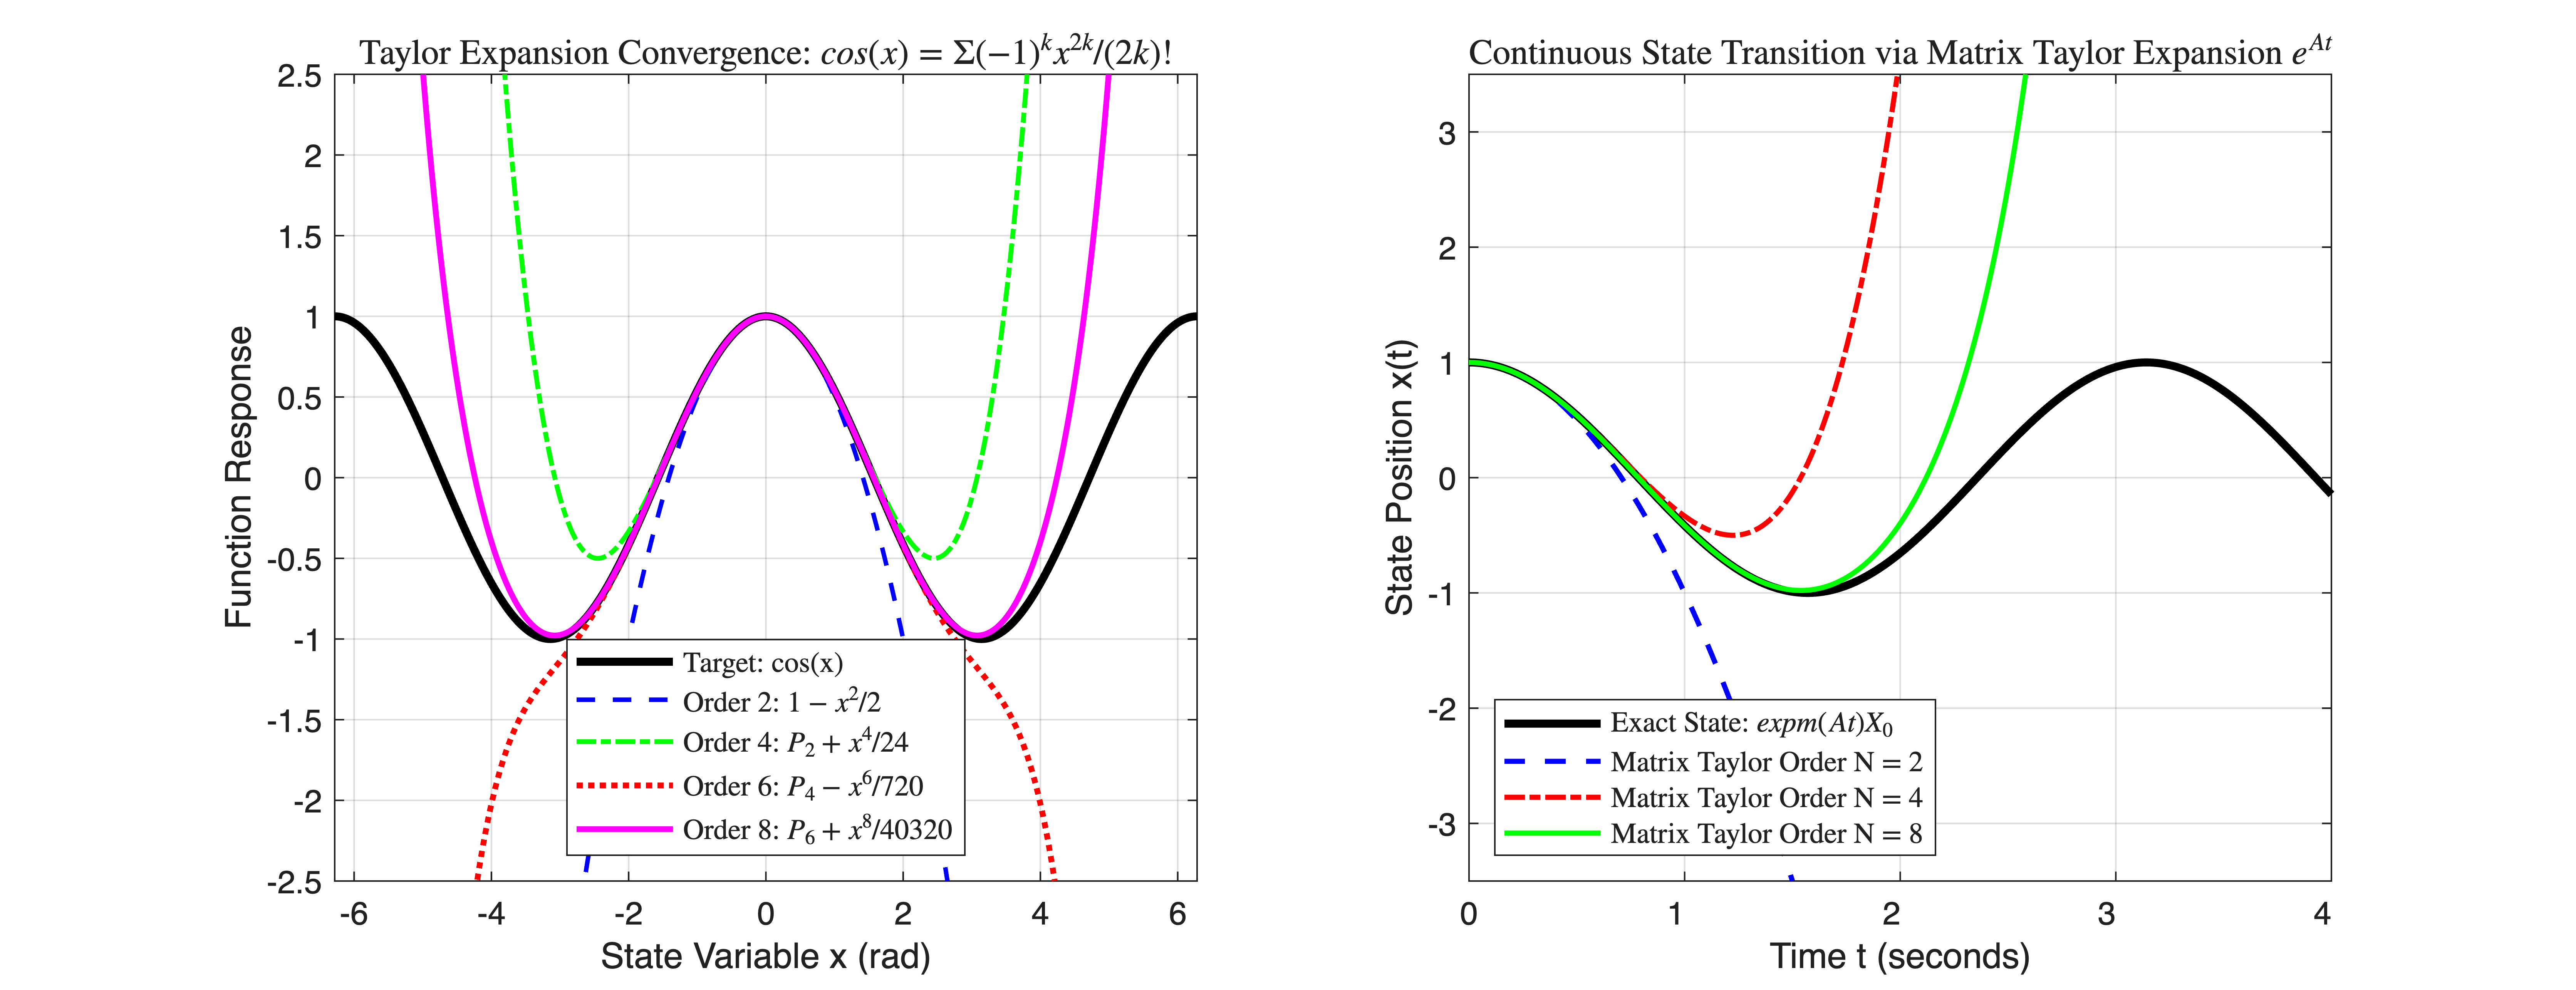

In [1]:
%% MIT 18.01 Lecture 37: Taylor Series & State Transition Matrix Simulation
% Mathematical Tool Application: Used for local Jacobian linearization of nonlinear
% plants around operating points, matrix exponential state transition modeling (e^{At}),
% and polynomial truncation error analysis for embedded real-time controllers.


clear; clc; close all;


%% Part 1: Taylor Polynomial Convergence & Truncation Residue: cos(x)
% True Target Function: f(x) = cos(x) on domain [-2*pi, 2*pi]
x_domain = linspace(-2*pi, 2*pi, 500);
y_true = cos(x_domain);


% Successive Maclaurin Taylor Polynomials derived in Lecture 37:
% P0(x) = 1
% P2(x) = 1 - x^2 / 2!
% P4(x) = 1 - x^2 / 2! + x^4 / 4!
% P6(x) = 1 - x^2 / 2! + x^4 / 4! - x^6 / 6!
P0 = ones(size(x_domain));
P2 = 1.0 - (x_domain.^2) / 2.0;
P4 = P2 + (x_domain.^4) / 24.0;
P6 = P4 - (x_domain.^6) / 720.0;
P8 = P6 + (x_domain.^8) / 40320.0;


figure('Color', 'w', 'Position', [100, 100, 1250, 480]);


subplot(1, 2, 1);
plot(x_domain, y_true, 'k-', 'LineWidth', 2.5, 'DisplayName', 'Target: cos(x)'); hold on;
plot(x_domain, P2, 'b--', 'LineWidth', 1.4, 'DisplayName', 'Order 2: $1 - x^2/2$');
plot(x_domain, P4, 'g-.', 'LineWidth', 1.5, 'DisplayName', 'Order 4: $P_2 + x^4/24$');
plot(x_domain, P6, 'r:',  'LineWidth', 1.8, 'DisplayName', 'Order 6: $P_4 - x^6/720$');
plot(x_domain, P8, 'm-',  'LineWidth', 1.8, 'DisplayName', 'Order 8: $P_6 + x^8/40320$');


grid on;
xlim([-2*pi, 2*pi]); ylim([-2.5, 2.5]);
xlabel('State Variable x (rad)');
ylabel('Function Response');
title('Taylor Expansion Convergence: $cos(x) = \Sigma (-1)^k x^{2k} / (2k)!$', 'Interpreter','latex');
legend('Location', 'south','Interpreter','latex');


%% Part 2: State Transition Matrix Exponential via Taylor Series e^{At}
% Plant: Undamped oscillator \ddot{x} + \omega_0^2 x = 0 (omega0 = 2 rad/s)
% State-Space Form: \dot{X} = A*X, where X = [x; \dot{x}]
subplot(1, 2, 2);
omega0 = 2.0;
A_mat = [0, 1; -(omega0^2), 0];


% Time simulation interval: t from 0 to 4 seconds
t_span = linspace(0, 4.0, 300);
X0 = [1.0; 0.0]; % Initial displacement = 1 m, initial velocity = 0


% 1. Benchmark Exact Trajectory via MATLAB expm: X(t) = expm(A*t)*X0
x_exact = zeros(size(t_span));
for i = 1:length(t_span)
    Phi_exact = expm(A_mat * t_span(i));
    X_curr = Phi_exact * X0;
    x_exact(i) = X_curr(1);
end


% 2. Truncated Matrix Taylor Series Approximations:
% Phi_N(t) = \sum_{k=0}^N (A*t)^k / k!
N_orders = [2, 4, 8];
colors_ode = {'b--', 'r-.', 'g-'};


plot(t_span, x_exact, 'k-', 'LineWidth', 2.5, 'DisplayName', 'Exact State: expm(At)X_0'); hold on;


for idx = 1:length(N_orders)
    N_deg = N_orders(idx);
    x_taylor = zeros(size(t_span));


    for i = 1:length(t_span)
        t_val = t_span(i);
        Phi_approx = zeros(2, 2);
        for k = 0:N_deg
            Phi_approx = Phi_approx + ((A_mat * t_val)^k) / factorial(k);
        end
        X_approx = Phi_approx * X0;
        x_taylor(i) = X_approx(1);
    end


    plot(t_span, x_taylor, colors_ode{idx}, 'LineWidth', 1.6, ...
        'DisplayName', sprintf('Matrix Taylor Order N = %d', N_deg));
end


grid on;
xlim([0, 4.0]); ylim([-3.5, 3.5]);
xlabel('Time t (seconds)');
ylabel('State Position x(t)');
title('Continuous State Transition via Matrix Taylor Expansion $e^{At}$', 'Interpreter','latex');
legend('Location', 'southwest', 'Interpreter','latex');